BANK MARKETING DATASET


IMPORT LIBRARIES

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from imblearn.over_sampling import SMOTE


from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_score, recall_score, f1_score

import joblib


LOAD DATASET

In [ ]:
Data = pd.read_csv('/content/bank_marketing_dataset.csv')
Data

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,subscribed
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


EXPLORE DATASET

In [ ]:
# first 5 rows

In [ ]:
Data.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,subscribed
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:
# last 5 rows

In [ ]:
Data.tail()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,subscribed
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,3,999,1,failure,-1.1,94.767,-50.8,1.028,4963.6,no


In [ ]:
# rows & columns

In [ ]:
Data.shape

(41188, 21)

In [ ]:

# total values

In [ ]:
Data.size

864948

In [ ]:

# dimensions

In [ ]:
Data.ndim

2

In [ ]:
# data types

In [ ]:
Data.dtypes

,0
age,int64
job,object
marital,object
education,object
default,object
housing,object
loan,object
contact,object
month,object
day_of_week,object


In [ ]:
# complete information

In [ ]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [ ]:
# statistics

In [ ]:
Data.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


DATA PREPROCESSING

In [ ]:
# missing values

In [ ]:
Data.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


In [ ]:
# duplicate values

In [ ]:
Data.duplicated().sum()

np.int64(12)

In [ ]:
# remove duplicate rows

In [ ]:
Data.drop_duplicates(inplace=True)

In [ ]:
# check duplicate values

In [ ]:
Data.duplicated().sum()

np.int64(0)

In [ ]:
# check data types

In [ ]:
Data.dtypes

,0
age,int64
job,object
marital,object
education,object
default,object
housing,object
loan,object
contact,object
month,object
day_of_week,object


IDENTIFY CATEGORICAL FEATURES


In [ ]:
Data.select_dtypes(include='object').columns

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome', 'subscribed'],
      dtype='object')

IDENTIFY NUMERICAL FEATURES

---



In [ ]:
Data.select_dtypes(include=['int64', 'float64']).columns

Index(['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='object')

ENCODE CATEGORICAL VARIABLES




In [ ]:
le = LabelEncoder()

for col in Data.select_dtypes(include='object').columns:
    Data[col] = le.fit_transform(Data[col])

In [ ]:
# check data types

In [ ]:

Data.dtypes

,0
age,int64
job,int64
marital,int64
education,int64
default,int64
housing,int64
loan,int64
contact,int64
month,int64
day_of_week,int64


In [ ]:
# outlier check


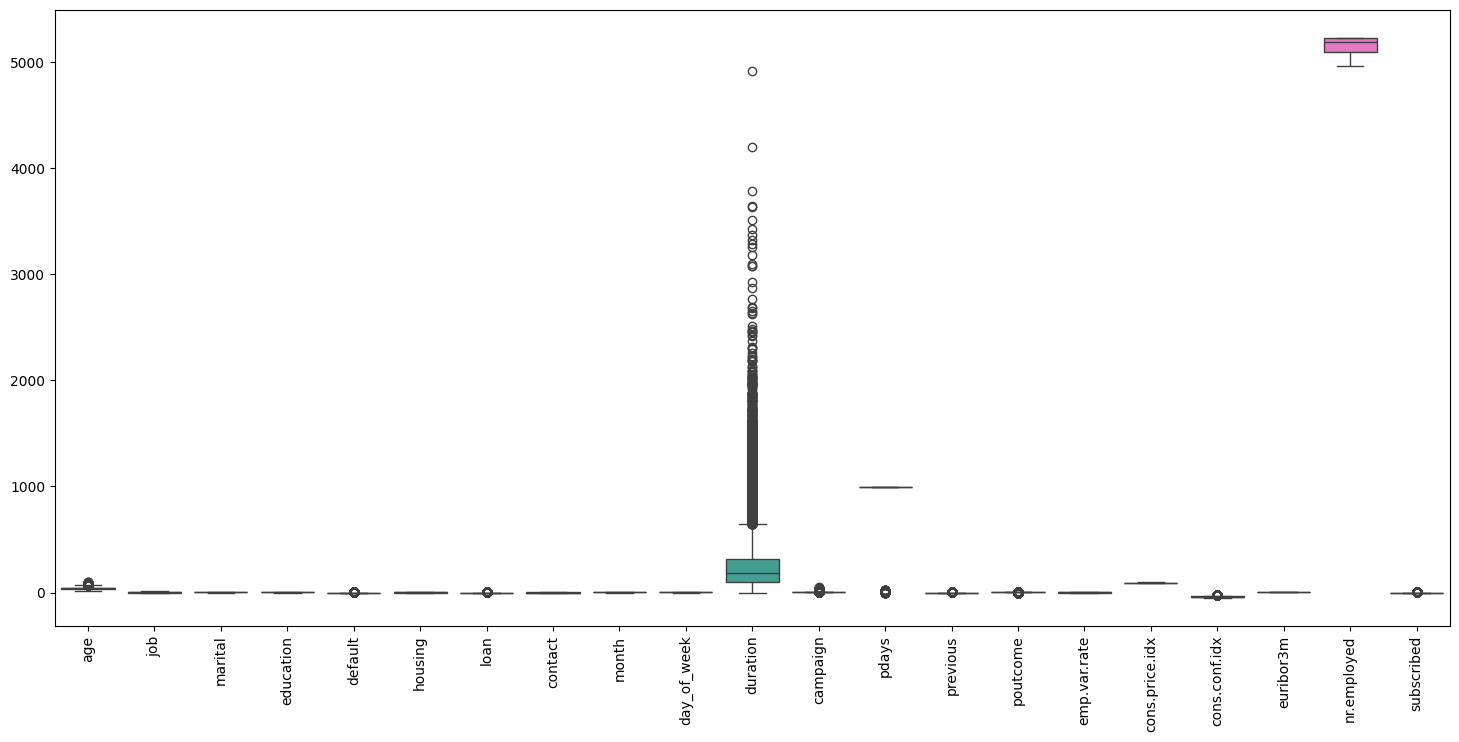

In [ ]:
plt.figure(figsize=(18,8))
sns.boxplot(data=Data)
plt.xticks(rotation=90)
plt.show()

In [ ]:
# correlation

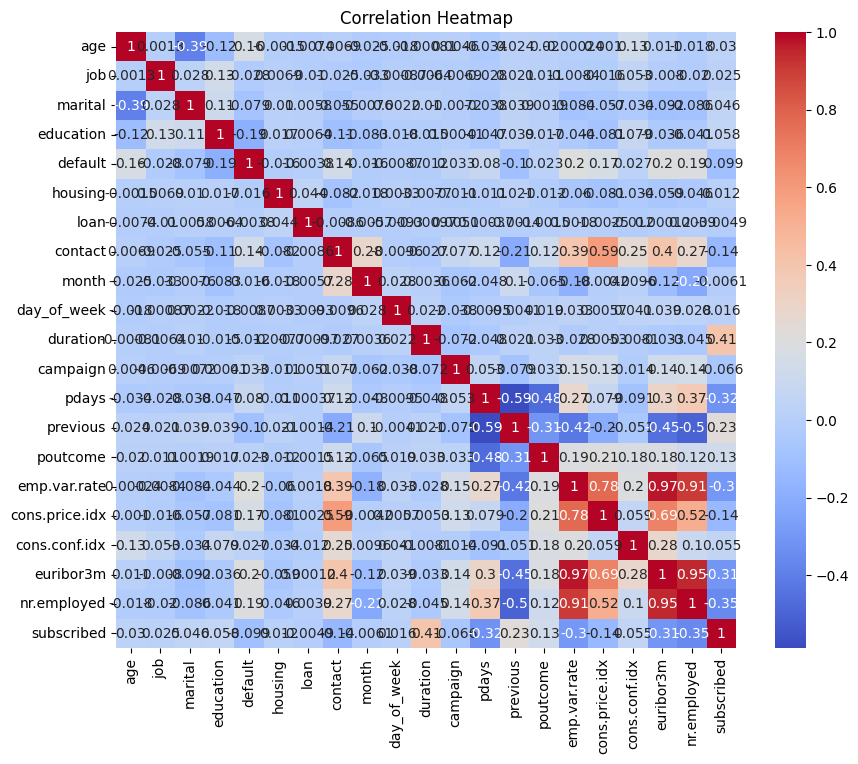

In [ ]:

correlation = Data.corr(numeric_only=True)

plt.figure(figsize=(10,8))
sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
# check dataset balance

In [ ]:
Data["subscribed"].value_counts()

,count
subscribed,
0,36537
1,4639


In [ ]:
#graph

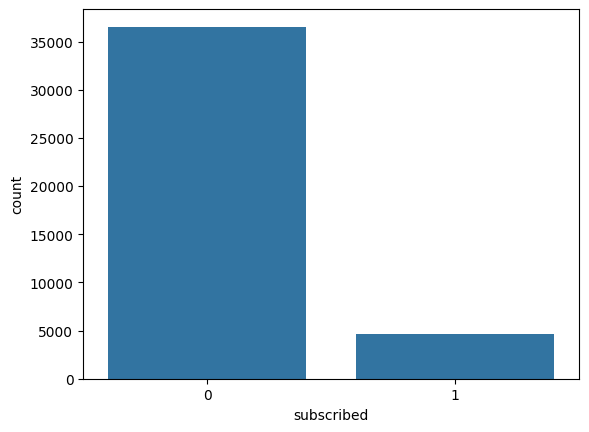

In [ ]:
sns.countplot(x='subscribed',data=Data)
plt.show()

FEATURES SELECTION


In [ ]:
x = Data.drop("subscribed", axis=1)
y = Data["subscribed"]

TRAIN TEST SPLIT

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42)

SMOTE

In [ ]:
smote = SMOTE(random_state=42)
x_train, y_train = smote.fit_resample(x_train, y_train)

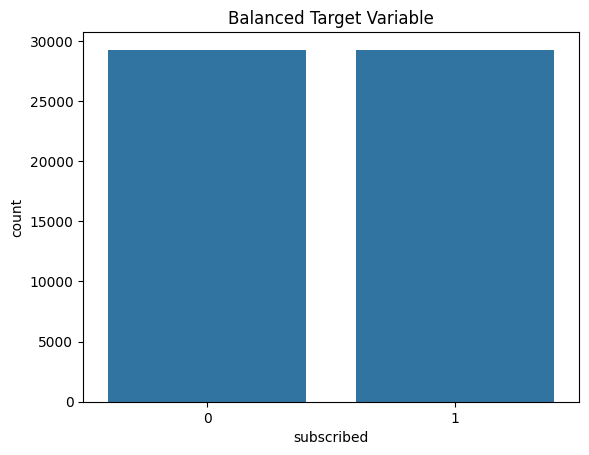

In [ ]:
sns.countplot(x=y_train)
plt.title("Balanced Target Variable")
plt.show()

FEATURE SCALING

In [ ]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

LOGISTIC REGRESSION


In [ ]:
lr = LogisticRegression()
lr.fit(x_train_scaled, y_train)

LogisticRegression()

DECISION TREE

In [ ]:

dt = DecisionTreeClassifier(random_state=42)
dt.fit(x_train, y_train)

DecisionTreeClassifier(random_state=42)

RANDOM FOREST

In [ ]:
rf = RandomForestClassifier(random_state=42)
rf.fit(x_train, y_train)

RandomForestClassifier(random_state=42)

KNN

In [ ]:
knn = KNeighborsClassifier()
knn.fit(x_train_scaled, y_train)

KNeighborsClassifier()

SVM

In [ ]:
svm = SVC()
svm .fit(x_train_scaled, y_train)

SVC()

MAKE PREDICTION

In [ ]:
# LOGISTIC REGRESSION

In [ ]:
y_pred_lr = lr.predict(x_test_scaled)


In [ ]:
y_pred_lr

array([1, 0, 1, ..., 0, 0, 0])

In [ ]:
# DECISION TREE

In [ ]:
y_pred_dt = dt.predict(x_test)


In [ ]:
y_pred_dt

array([1, 0, 1, ..., 0, 0, 0])

In [ ]:
# RANDOM FOREST

In [ ]:
y_pred_rf = rf.predict(x_test)


In [ ]:
y_pred_rf

array([0, 0, 1, ..., 0, 0, 0])

In [ ]:
# KNN

In [ ]:
y_pred_knn = knn.predict(x_test_scaled)


In [ ]:
y_pred_knn

array([1, 0, 1, ..., 0, 0, 0])

In [ ]:
# SVM


In [ ]:
y_pred_svm = svm.predict(x_test_scaled)


In [ ]:
y_pred_svm

array([1, 0, 1, ..., 0, 0, 0])

EVALUATE THE MODELS

In [ ]:
# LOGISTIC REGRESSION

In [ ]:
accuracy_score(y_test, y_pred_lr)

0.8603691112190384

In [ ]:
confusion_matrix(y_test, y_pred_lr)

array([[6345,  920],
       [ 230,  741]])

In [ ]:
classification_report(y_test, y_pred_lr)

'              precision    recall  f1-score   support\n\n           0       0.97      0.87      0.92      7265\n           1       0.45      0.76      0.56       971\n\n    accuracy                           0.86      8236\n   macro avg       0.71      0.82      0.74      8236\nweighted avg       0.90      0.86      0.88      8236\n'

In [ ]:
precision_score(y_test, y_pred_lr)

0.4461167971101746

In [ ]:
recall_score(y_test, y_pred_lr)

0.7631307929969104

In [ ]:
f1_score(y_test, y_pred_lr)

0.5630699088145896

In [ ]:
# DECISION TREE

In [ ]:
accuracy_score(y_test, y_pred_dt)

0.8739679456046625

In [ ]:
confusion_matrix(y_test, y_pred_dt)

array([[6665,  600],
       [ 438,  533]])

In [ ]:
classification_report(y_test, y_pred_dt)

'              precision    recall  f1-score   support\n\n           0       0.94      0.92      0.93      7265\n           1       0.47      0.55      0.51       971\n\n    accuracy                           0.87      8236\n   macro avg       0.70      0.73      0.72      8236\nweighted avg       0.88      0.87      0.88      8236\n'

In [ ]:
precision_score(y_test, y_pred_dt)

0.470432480141218

In [ ]:
recall_score(y_test, y_pred_dt)

0.548918640576725

In [ ]:
f1_score(y_test, y_pred_dt)

0.5066539923954373

In [ ]:
# RANDOM FOREST

In [ ]:
accuracy_score(y_test, y_pred_rf)

0.9066294317629917

In [ ]:

confusion_matrix(y_test, y_pred_rf)

array([[6834,  431],
       [ 338,  633]])

In [ ]:
classification_report(y_test, y_pred_rf)

'              precision    recall  f1-score   support\n\n           0       0.95      0.94      0.95      7265\n           1       0.59      0.65      0.62       971\n\n    accuracy                           0.91      8236\n   macro avg       0.77      0.80      0.78      8236\nweighted avg       0.91      0.91      0.91      8236\n'

In [ ]:
precision_score(y_test, y_pred_rf)

0.5949248120300752

In [ ]:
recall_score(y_test, y_pred_rf)

0.6519052523171988

In [ ]:
f1_score(y_test, y_pred_rf)

0.6221130221130221

In [ ]:
# KNN

In [ ]:
accuracy_score(y_test, y_pred_knn)

0.8686255463817387

In [ ]:
confusion_matrix(y_test, y_pred_knn)

array([[6531,  734],
       [ 348,  623]])

In [ ]:
classification_report(y_test, y_pred_knn)

'              precision    recall  f1-score   support\n\n           0       0.95      0.90      0.92      7265\n           1       0.46      0.64      0.54       971\n\n    accuracy                           0.87      8236\n   macro avg       0.70      0.77      0.73      8236\nweighted avg       0.89      0.87      0.88      8236\n'

In [ ]:
precision_score(y_test, y_pred_knn)

0.4591009579955785

In [ ]:
recall_score(y_test, y_pred_knn)

0.6416065911431514

In [ ]:
f1_score(y_test, y_pred_knn)

0.5352233676975945

In [ ]:
# SVM

In [ ]:
accuracy_score(y_test, y_pred_svm)

0.879553181155901

In [ ]:
confusion_matrix(y_test, y_pred_svm)

array([[6528,  737],
       [ 255,  716]])

In [ ]:
classification_report(y_test, y_pred_svm)

'              precision    recall  f1-score   support\n\n           0       0.96      0.90      0.93      7265\n           1       0.49      0.74      0.59       971\n\n    accuracy                           0.88      8236\n   macro avg       0.73      0.82      0.76      8236\nweighted avg       0.91      0.88      0.89      8236\n'

In [ ]:
precision_score(y_test, y_pred_svm)

0.4927735719201652

In [ ]:
recall_score(y_test, y_pred_svm)

0.737384140061792

In [ ]:
f1_score(y_test, y_pred_svm)

0.5907590759075908

COMPARE MULTIPLE ALGORITHM

In [ ]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest", "KNN", "SVM"],
    "Accuracy":[
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm)
    ]
})
comparison

,Model,Accuracy
0,Logistic Regression,0.860369
1,Decision Tree,0.873968
2,Random Forest,0.906629
3,KNN,0.868626
4,SVM,0.879553


In [ ]:
comparison.sort_values(by="Accuracy", ascending=False)

,Model,Accuracy
2,Random Forest,0.906629
4,SVM,0.879553
1,Decision Tree,0.873968
3,KNN,0.868626
0,Logistic Regression,0.860369


SAVE BEST MODEL

In [ ]:
joblib.dump(rf, "best_model.pkl")

['best_model.pkl']

SAVE SCALER

In [ ]:
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

LOAD MODEL

In [ ]:
model = joblib.load("best_model.pkl")
scaler = joblib.load("scaler.pkl")

PREDICT NEW DATA

In [ ]:
# label mapping for categorical features

In [ ]:
Data = pd.read_csv("/content/bank_marketing_dataset.csv")

In [ ]:
categorical_columns = ['job', 'marital', 'education', 'default',

                       'housing', 'loan', 'contact',

                       'month', 'day_of_week', 'poutcome']

for col in categorical_columns:

    le = LabelEncoder()

    le.fit(Data[col])

    print(f"\n{col} Mapping")

    print(dict(zip(le.classes_, le.transform(le.classes_))))


job Mapping
{'admin.': np.int64(0), 'blue-collar': np.int64(1), 'entrepreneur': np.int64(2), 'housemaid': np.int64(3), 'management': np.int64(4), 'retired': np.int64(5), 'self-employed': np.int64(6), 'services': np.int64(7), 'student': np.int64(8), 'technician': np.int64(9), 'unemployed': np.int64(10), 'unknown': np.int64(11)}

marital Mapping
{'divorced': np.int64(0), 'married': np.int64(1), 'single': np.int64(2), 'unknown': np.int64(3)}

education Mapping
{'basic.4y': np.int64(0), 'basic.6y': np.int64(1), 'basic.9y': np.int64(2), 'high.school': np.int64(3), 'illiterate': np.int64(4), 'professional.course': np.int64(5), 'university.degree': np.int64(6), 'unknown': np.int64(7)}

default Mapping
{'no': np.int64(0), 'unknown': np.int64(1), 'yes': np.int64(2)}

housing Mapping
{'no': np.int64(0), 'unknown': np.int64(1), 'yes': np.int64(2)}

loan Mapping
{'no': np.int64(0), 'unknown': np.int64(1), 'yes': np.int64(2)}

contact Mapping
{'cellular': np.int64(0), 'telephone': np.int64(1)}

mo

In [ ]:
# user input

In [ ]:
age = int(input("Enter Age: "))

job = int(input("Enter Job (encoded): "))

marital = int(input("Enter Marital Status (encoded): "))

education = int(input("Enter Education (encoded): "))

default = int(input("Enter Default (encoded): "))

housing = int(input("Enter Housing Loan (encoded): "))

loan = int(input("Enter Personal Loan (encoded): "))

contact = int(input("Enter Contact Type (encoded): "))

month = int(input("Enter Month (encoded): "))

day_of_week = int(input("Enter Day of Week (encoded): "))

duration = int(input("Enter Duration: "))

campaign = int(input("Enter Campaign: "))

pdays = int(input("Enter Pdays: "))

previous = int(input("Enter Previous: "))

poutcome = int(input("Enter Previous Outcome (encoded): "))

emp_var_rate = float(input("Enter Employment Variation Rate: "))

cons_price_idx = float(input("Enter Consumer Price Index: "))

cons_conf_idx = float(input("Enter Consumer Confidence Index: "))

euribor3m = float(input("Enter Euribor3m: "))

nr_employed = float(input("Enter Number of Employees: "))



# new_data

new_data = [[

    age, job, marital, education, default,

    housing, loan, contact, month, day_of_week,

    duration, campaign, pdays, previous, poutcome,

    emp_var_rate, cons_price_idx, cons_conf_idx,

    euribor3m, nr_employed

]]


# feature scaling

new_data = scaler.transform(new_data)


# prediction

prediction = model.predict(new_data)

Enter Age: 35
Enter Job (encoded): 2
Enter Marital Status (encoded): 1
Enter Education (encoded): 0
Enter Default (encoded): 2
Enter Housing Loan (encoded): 0
Enter Personal Loan (encoded): 0
Enter Contact Type (encoded): 0
Enter Month (encoded): 5
Enter Day of Week (encoded): 3
Enter Duration: 5
Enter Campaign: 100
Enter Pdays: 4
Enter Previous: 41
Enter Previous Outcome (encoded): 1
Enter Employment Variation Rate: 12
Enter Consumer Price Index: 22
Enter Consumer Confidence Index: 1
Enter Euribor3m: 12
Enter Number of Employees: 12


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
# result

In [ ]:
if prediction[0] == 1:
    print("customer will subscribe")
else:
    print("customer will not subscribe")

customer will not subscribe
